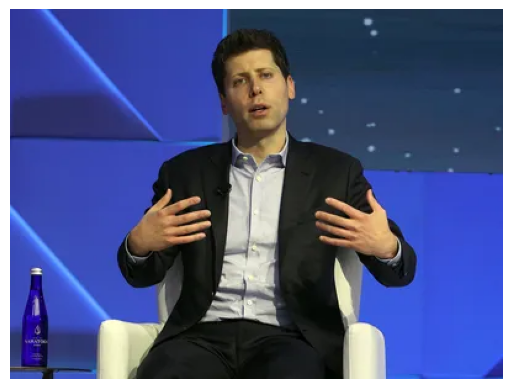

In [4]:
# EX 2

import urllib.request
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

image_url = 'https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/images/Altman.webp'
image = Image.open(urllib.request.urlopen(image_url))

# Conversia imaginii într-un array pentru a fi folosit cu matplotlib
img_array = np.array(image)

plt.imshow(img_array)
plt.axis('off')
plt.show()



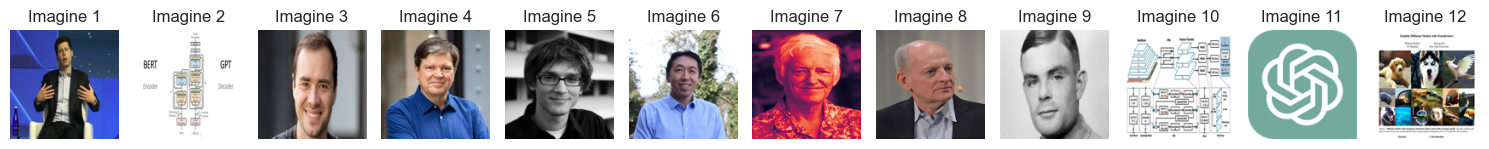

In [2]:
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

base_url = 'https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/images/'

image_files = ['Altman.webp', 'BERT.png', 'Karpaty.jpg', 'LeCun.jpg', 'Leskovec.jpg', 'Ng.webp', 'Norvig.jpg', 'Russell.jpg',
               'Turing.webp', 'YOLO.jpg', 'chatGPT.png', 'diffusionModel.jpg']

defin, axes = plt.subplots(1, len(image_files), figsize=(15, 5))

for i, image_file in enumerate(image_files):

    image_url = base_url + image_file
    image = Image.open(urllib.request.urlopen(image_url))
    image = image.resize((128, 128))

    img_array = np.array(image)

    axes[i].imshow(img_array)
    axes[i].axis('off')
    axes[i].set_title(f"Imagine {i+1}")


plt.tight_layout()
plt.show()


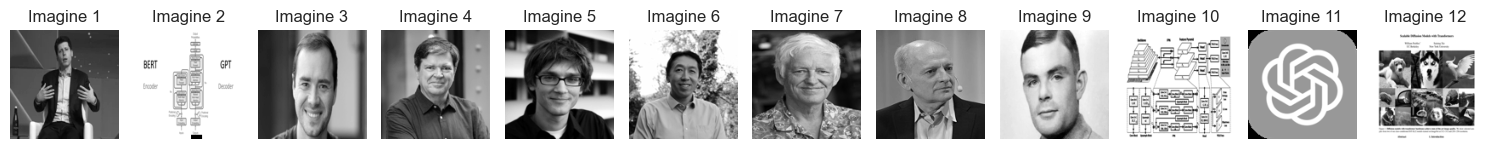

In [6]:
defin, axes = plt.subplots(1, len(image_files), figsize=(15, 5))

for i, image_file in enumerate(image_files):

    image_url = base_url + image_file
    image = Image.open(urllib.request.urlopen(image_url))
    image = image.resize((128, 128)) # sa fie 128px pe 128px

    # imaginine -> format gray-level
    image_gray = image.convert('L')  # 'L' pentru tonuri de gri

    img_array = np.array(image_gray)

    axes[i].imshow(img_array, cmap='gray')  # cmap pentru a afișa imaginea în tonuri de gri
    axes[i].axis('off')
    axes[i].set_title(f"Imagine {i+1}")


plt.tight_layout()
plt.show()

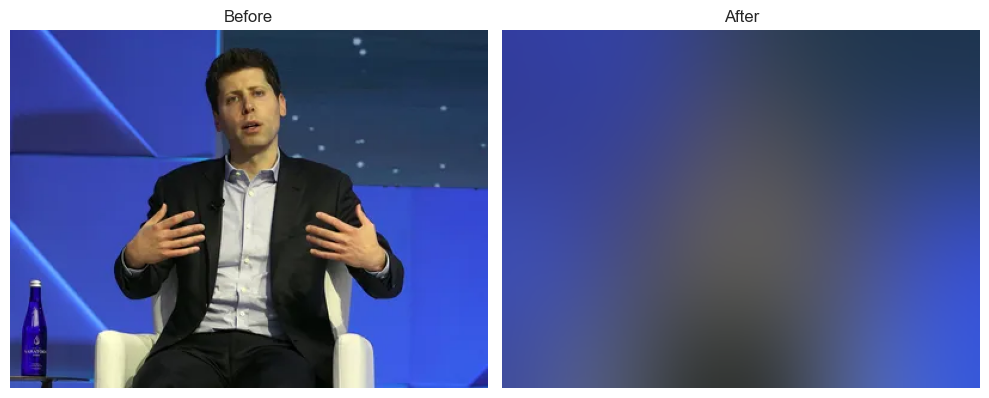

In [8]:
from PIL import Image, ImageFilter

imagine_nume = 'Altman.webp'
url_imagine = base_url + imagine_nume
imagine = Image.open(urllib.request.urlopen(url_imagine))

imagine_blurred = imagine.filter(ImageFilter.GaussianBlur(radius=50))

defin, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(np.array(imagine))
axes[0].axis('off')
axes[0].set_title("Before")

axes[1].imshow(np.array(imagine_blurred))
axes[1].axis('off')
axes[1].set_title("After")

plt.tight_layout()
plt.show()


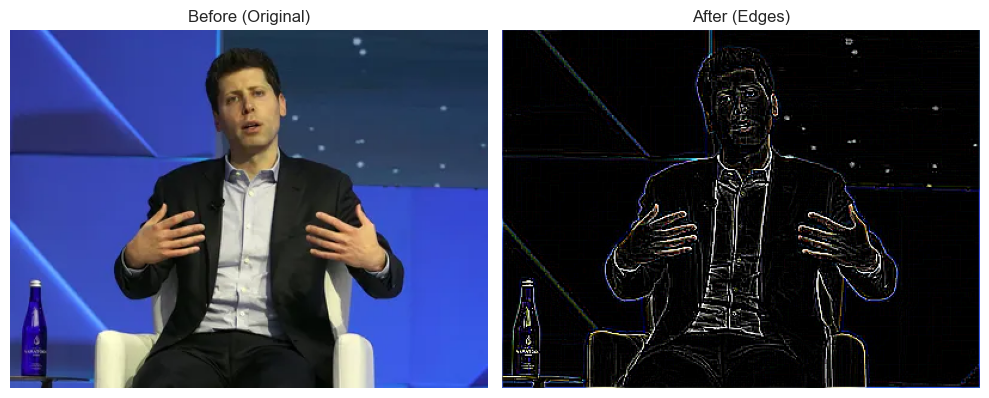

In [6]:
from PIL import Image, ImageFilter

imagine_nume = 'Altman.webp'
url_imagine = base_url + imagine_nume
imagine = Image.open(urllib.request.urlopen(url_imagine))


# filtrul FIND_EDGES pentru detecția muchiilor
edges_imagine = imagine.filter(ImageFilter.FIND_EDGES)

var, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(imagine)
axes[0].axis('off')
axes[0].set_title("Before (Original)")

axes[1].imshow(edges_imagine)
axes[1].axis('off')
axes[1].set_title("After (Edges)")

# Afișarea imaginilor
plt.tight_layout()
plt.show()


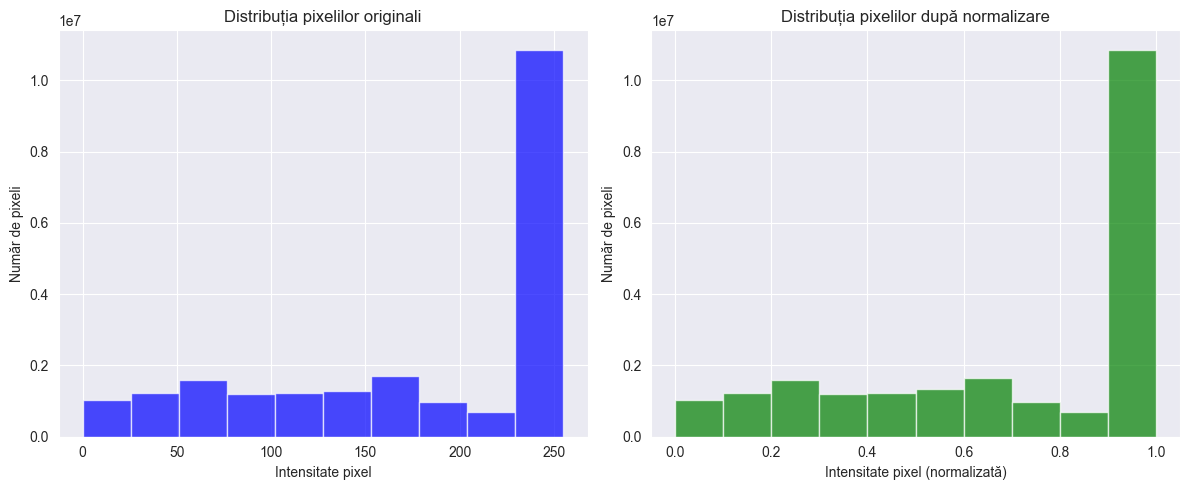

In [7]:
# NORMALIARE
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request

base_url = 'https://raw.githubusercontent.com/lauradiosan/AI-UBB/refs/heads/main/2024-2025/labs/lab02/data/images/'

files = ['Altman.webp', 'BERT.png', 'Karpaty.jpg', 'LeCun.jpg', 'Leskovec.jpg', 'Ng.webp', 'Norvig.jpg', 'Russell.jpg',
               'Turing.webp', 'YOLO.jpg', 'chatGPT.png', 'diffusionModel.jpg']

all_images = []

for image_file in files:
    image_url = base_url + image_file
    image = Image.open(urllib.request.urlopen(image_url))
    img_array = np.array(image) # img -> array NumPy (matrice tridimensională de pixeli: [înălțime, lățime, canale de culoare])
    all_images.append(img_array)

all_images_array = np.concatenate([img.flatten() for img in all_images]) # toți vectorii -> array mare cu toți pixelii imaginilor
                                                        # pt normalizarea pixelilor pe tot setul de imagini
min_val = np.min(all_images_array)
max_val = np.max(all_images_array) # minimul si maximul pixelilor

# X_norm = (X - X_min)/(X_max - X_min)

all_images_array_normalized = (all_images_array - min_val) / (max_val - min_val)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# hist pixeli originali
axes[0].hist(all_images_array, color='blue', alpha=0.7)
axes[0].set_title("Distribuția pixelilor originali")
axes[0].set_xlabel("Intensitate pixel")
axes[0].set_ylabel("Număr de pixeli")

# hist pixeli normalizați
axes[1].hist(all_images_array_normalized, color='green', alpha=0.7)
axes[1].set_title("Distribuția pixelilor după normalizare")
axes[1].set_xlabel("Intensitate pixel (normalizată)")
axes[1].set_ylabel("Număr de pixeli")

plt.tight_layout()
plt.show()
